In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Map to your Google Drive paths
# Verify these match exactly how the folders are named in your Drive
CSV_PATH = '/content/drive/MyDrive/Dibetes_DL_Model/B. Disease Grading/2. Groundtruths/a. IDRiD_Disease Grading_Training Labels.csv'
IMAGE_DIR = '/content/drive/MyDrive/Dibetes_DL_Model/B. Disease Grading/1. Original Images/a. Training Set'


# 2. Load and format the labels
df = pd.read_csv(CSV_PATH)
df['Image name'] = df['Image name'].apply(lambda x: f"{x}.jpg")
df['Retinopathy grade'] = df['Retinopathy grade'].astype(str)

# 3. Create a Stratified Train/Validation Split (80/20)
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['Retinopathy grade'],
    random_state=42
)

# 4. Initialize Data Generators
from tensorflow.keras.applications.resnet50 import preprocess_input

# rescale=1./255 hata kar preprocessing_function lagao
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=15,
    zoom_range=0.1
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# 5. Build the Data Pipelines
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=IMAGE_DIR,
    x_col='Image name',
    y_col='Retinopathy grade',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    directory=IMAGE_DIR,
    x_col='Image name',
    y_col='Retinopathy grade',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 330 validated image filenames belonging to 5 classes.
Found 83 validated image filenames belonging to 5 classes.


In [15]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense

# 1. Load the pre-trained ResNet50 base model
# include_top=False removes the original 1000-class ImageNet output layer
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# 2. Freeze the base model
# This prevents the pre-trained weights from being destroyed during initial training
base_model.trainable = False

# 3. Build the custom classification head
model = Sequential([
    base_model,

    # Condenses the feature maps into a 1D vector
    GlobalAveragePooling2D(),

    # Adds a 40% dropout rate to randomly disable neurons, preventing overfitting
    Dropout(0.4),

    # The final output layer with 5 neurons (for grades 0, 1, 2, 3, 4)
    # softmax converts the outputs into probability percentages
    Dense(5, activation='softmax')
])

# 4. Compile the model
# categorical_crossentropy is used because our pipeline one-hot encoded the labels
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# View the architecture summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [16]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# 1. Calculate Class Weights
# extract the unique classes and the actual labels from your training DataFrame
unique_classes = np.unique(train_df['Retinopathy grade'])
y_train = train_df['Retinopathy grade']

# 'balanced' automatically assigns higher numbers to rare classes
weights_array = compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_train
)

# Keras requires the weights to be formatted as a dictionary: {class_index: weight}
# The indices (0-4) must match the one-hot encoded output of your generator
class_weights_dict = {i: weight for i, weight in enumerate(weights_array)}
print(f"Computed Class Weights: {class_weights_dict}")

# 2. Configure Callbacks
# Monitoring val_loss is the most reliable way to diagnose and prevent overfitting.
# Training will halt if the validation loss fails to decrease for 5 consecutive epochs.
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Saves the optimal weights to your local drive or mounted Google Drive
model_checkpoint = ModelCheckpoint(
    filepath='idrid_resnet50_best.keras',
    monitor='val_loss',
    save_best_only=True
)

# 3. Execute Training
# Pass the data generators, class weights, and callbacks into the fit method.
# If running locally on your laptop rather than Colab, the first epoch will take the longest
# as the pipeline loads and resizes the high-resolution images from the disk.
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    class_weight=class_weights_dict,
    callbacks=[early_stopping, model_checkpoint]
)

Computed Class Weights: {0: np.float64(0.616822429906542), 1: np.float64(4.125), 2: np.float64(0.6055045871559633), 3: np.float64(1.11864406779661), 4: np.float64(1.6923076923076923)}
Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 137s 12s/step - accuracy: 0.3182 - loss: 2.9444 - val_accuracy: 0.3133 - val_loss: 1.8371
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 121s 11s/step - accuracy: 0.2970 - loss: 2.4155 - val_accuracy: 0.3855 - val_loss: 1.5359
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 142s 11s/step - accuracy: 0.2697 - loss: 1.9639 - val_accuracy: 0.3494 - val_loss: 1.4786
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 137s 13s/step - accuracy: 0.2545 - loss: 1.9572 - val_accuracy: 0.3614 - val_loss: 1.4777
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 120s 11s/step - accuracy: 0.2212 - loss: 1.9684 - val_accuracy: 0.3976 - val_loss: 1.4733
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 143s 11s/step - accuracy: 0.2515 - loss: 2.0090 - val_accuracy: 0.4096 - val_loss: 1.4616
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 137s 12s/s

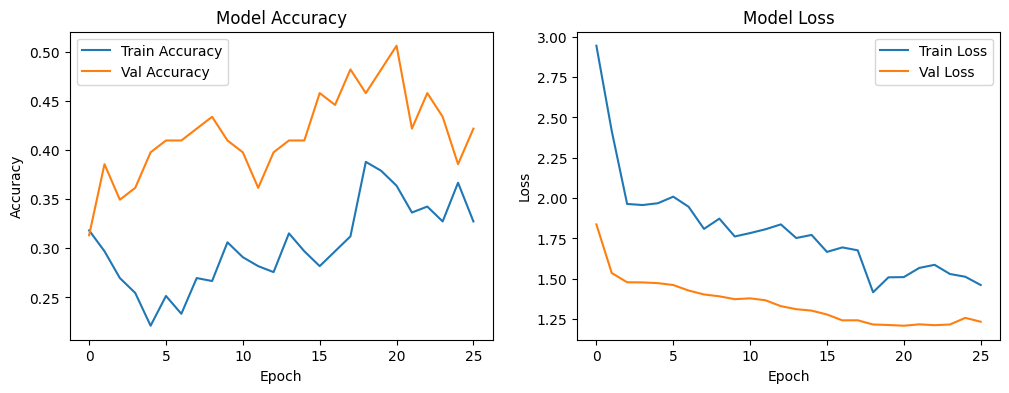

In [17]:
import matplotlib.pyplot as plt

# Accuracy Graph
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss Graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 29s 7s/step
Classification Report:

              precision    recall  f1-score   support

     Grade 0       0.79      0.70      0.75        27
     Grade 1       0.20      0.50      0.29         4
     Grade 2       0.44      0.41      0.42        27
     Grade 3       0.56      0.33      0.42        15
     Grade 4       0.33      0.50      0.40        10

    accuracy                           0.51        83
   macro avg       0.46      0.49      0.45        83
weighted avg       0.55      0.51      0.52        83



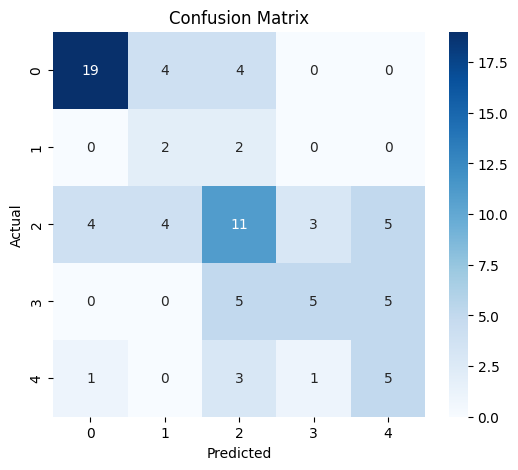

In [18]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# predictions on Validation data
val_generator.reset()
predictions = model.predict(val_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = val_generator.classes

# Classification Report
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=['Grade 0', 'Grade 1', 'Grade 2', 'Grade 3', 'Grade 4']))

# Confusion Matrix plot
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=[0,1,2,3,4], yticklabels=[0,1,2,3,4])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [19]:
model.save('/content/drive/MyDrive/idrid_final_model.keras')

In [20]:
from google.colab import files
files.download('/content/drive/MyDrive/idrid_final_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
!pip install -q gradio

In [26]:
import gradio as gr
import tensorflow as tf
import numpy as np
from tensorflow.keras.applications.resnet50 import preprocess_input

# 1. Load the trained model from Google Drive
MODEL_PATH = '/content/drive/MyDrive/idrid_final_model.keras'
model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = [
    "Grade 0 — No Apparent Retinopathy",
    "Grade 1 — Mild Non-Proliferative DR",
    "Grade 2 — Moderate Non-Proliferative DR",
    "Grade 3 — Severe Non-Proliferative DR",
    "Grade 4 — Proliferative DR"
]

CLINICAL_NOTES = {
    0: "No retinal abnormalities detected. Routine annual screening is typically recommended.",
    1: "Microaneurysms only. Early-stage signs detected; periodic monitoring is advised.",
    2: "More than microaneurysms, but less than severe NPDR. Follow-up with an ophthalmologist is recommended.",
    3: "Extensive intraretinal hemorrhages or venous beading. Prompt specialist evaluation is strongly advised.",
    4: "Signs of neovascularization or vitreous hemorrhage. Immediate ophthalmological consultation is required."
}

# 2. Inference function
def predict_dr(image):
    if image is None:
        return None, "⚠️ **No image uploaded.** Please upload a retinal fundus photograph to begin analysis."

    # Preprocess image for ResNet50
    img = image.convert("RGB").resize((224, 224))
    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    # Run prediction
    preds = model.predict(img_array, verbose=0)[0]
    top_idx = int(np.argmax(preds))
    confidence = float(preds[top_idx]) * 100

    probabilities = {CLASS_NAMES[i]: float(preds[i]) for i in range(5)}

    summary_md = f"""
    ### Diagnostic Summary
    * **Predicted Severity:** {CLASS_NAMES[top_idx]}
    * **Model Confidence:** {confidence:.2f}%
    * **Clinical Context:** {CLINICAL_NOTES[top_idx]}
    """
    return probabilities, summary_md

# 3. Custom Professional UI using Gradio Blocks
theme = gr.themes.Soft(
    primary_hue="blue",
    secondary_hue="slate",
    neutral_hue="slate",
    font=gr.themes.GoogleFont("Inter")
)

with gr.Blocks(theme=theme, title="Diabetic Retinopathy Screening Assistant") as demo:
    # Header
    gr.Markdown(
        """
        # 👁️ Diabetic Retinopathy Severity Screening
        **AI-Assisted Fundus Image Classification** | Powered by ResNet50 & IDRiD Dataset

        Upload a high-resolution retinal fundus photograph below to evaluate Diabetic Retinopathy (DR) severity across five standardized clinical grades (0–4).
        """
    )

    gr.HTML("<hr style='margin: 10px 0 20px 0; border-color: #e2e8f0;'>")

    # Main Two-Column Layout
    with gr.Row(equal_height=False):
        with gr.Column(scale=1):
            image_input = gr.Image(
                type="pil",
                label="Retinal Fundus Photograph",
                height=340
            )
            with gr.Row():
                clear_btn = gr.ClearButton(value="Clear", variant="secondary")
                analyze_btn = gr.Button(value="Analyze Scan", variant="primary")

        with gr.Column(scale=1):
            label_output = gr.Label(
                num_top_classes=5,
                label="Severity Grade Probability Distribution"
            )
            summary_output = gr.Markdown(
                value="### Diagnostic Summary\n*Upload a retinal scan and click **Analyze Scan** to view the assessment.*"
            )

    # Clinical Terminology & Grade Guide
    with gr.Accordion("Understanding Diabetic Retinopathy Grades (0–4)", open=False):
        gr.Markdown(
            """
            **Diabetic Retinopathy (DR)** is a diabetes-related eye condition caused by damage to the blood vessels of the light-sensitive tissue at the back of the eye (the retina). It progresses through two main stages:

            * **Non-Proliferative DR (NPDR — Grades 1 to 3):** The early-to-moderate stage where existing retinal blood vessels weaken, bulge, or leak fluid/blood into the retina, without new abnormal vessels growing yet.
            * **Proliferative DR (PDR — Grade 4):** The advanced stage where severe oxygen deprivation triggers the growth of fragile, abnormal new blood vessels (*neovascularization*) that can bleed into the eye and threaten vision.

            | Grade | Classification | Clinical Meaning |
            | :--- | :--- | :--- |
            | **Grade 0** | **No Apparent Retinopathy** | Healthy retina with no visible diabetic vascular abnormalities. |
            | **Grade 1** | **Mild Non-Proliferative DR** | Earliest stage; characterized by small, balloon-like swellings in tiny blood vessels (*microaneurysms*). |
            | **Grade 2** | **Moderate Non-Proliferative DR** | Blood vessels begin to lose their ability to transport blood, leading to retinal hemorrhages and fluid leakage. |
            | **Grade 3** | **Severe Non-Proliferative DR** | Significant blockage of retinal blood supply, causing widespread hemorrhages and signaling the retina to grow new vessels. |
            | **Grade 4** | **Proliferative DR** | Advanced stage involving abnormal new blood vessel growth, carrying a high risk of severe vision loss or retinal detachment. |
            """
        )

    # Collapsible Technical Details & Medical Disclaimer
    with gr.Accordion("Model Specifications & Medical Disclaimer", open=False):
        gr.Markdown(
            """
            * **Architecture:** ResNet50 (Transfer Learning with custom classification head)
            * **Dataset:** Indian Diabetic Retinopathy Image Dataset (IDRiD)
            * **Input Resolution:** 224 × 224 px (RGB)
            * **Disclaimer:** *This application is a research and educational prototype. It is not a certified medical device and should not be used as a substitute for professional clinical diagnosis or ophthalmological evaluation.*
            """
        )

    # Footer
    gr.Markdown(
        """
        ---
        <div style="text-align: center; color: #64748b; font-size: 0.9em;">
            Developed by <strong>Aryan Srivastava</strong> | Contact: <a href="mailto:aryansrivastava737@gmail.com">aryansrivastava737@gmail.com</a>
        </div>
        """
    )

    # Button Actions
    analyze_btn.click(
        fn=predict_dr,
        inputs=image_input,
        outputs=[label_output, summary_output]
    )
    clear_btn.add([image_input, label_output, summary_output])

# Launch with a public shareable link
demo.launch(share=True)

/tmp/ipykernel_3346/2448819669.py:60: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=theme, title="Diabetic Retinopathy Screening Assistant") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://898b79646d0d672bb9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
